In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data.labels import load_labels
from src.data.split_data import split_patients
from src.data.dataloader import build_dataloader

NEW LABELS.PY LOADED


In [2]:
csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)
labels, summary = load_labels(csv_path)

In [3]:
train_ids, val_ids, test_ids = split_patients(labels)

In [4]:
train_loader = build_dataloader(
    patient_ids=train_ids,
    labels=labels,
    image_dir="../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images",
    batch_size=8,
    shuffle=True,
)

In [5]:
print(len(train_loader))

2335


In [6]:
batch = next(iter(train_loader))

In [7]:
batch.keys()

dict_keys(['image', 'target', 'patient_ids'])

In [8]:
batch["image"].shape

torch.Size([8, 1, 512, 512])

In [9]:
batch["target"]

tensor([0, 0, 1, 1, 0, 0, 0, 0])

In [11]:
batch["patient_ids"]

['cd33df08-bfe1-4185-8c7d-9beea36b60f1',
 '88035956-1e69-4f8f-a9cb-fc3c471b03d3',
 '088b89f6-6847-4a20-b1ad-5887b56bbae7',
 '7798d157-4dbf-402c-8b93-d3b97cb29d64',
 '83fa7e9b-cdfa-499d-88cc-278de00fbbbf',
 '8eff11d0-2aa4-4033-8e25-3956bc0568b1',
 'ef1990ba-93ab-4713-985b-e9db3c62c2c6',
 'ef141030-96d6-4732-be12-bbce13bfda1e']

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

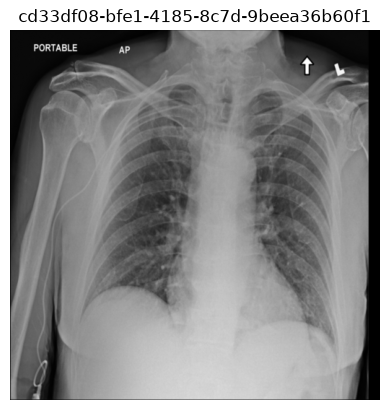

In [13]:
import matplotlib.pyplot as plt

plt.imshow(
    batch["image"][0][0],
    cmap="gray"
)

plt.title(batch["patient_ids"][0])

plt.axis("off")